# 04. 변수 선정: 처음 14개 → 최종 11개 (상관계수 기반 검토)
**A. 처음 14개 → 11개** (1차 모델에서 쓴 14개 변수)
- 월: 연중주차와 거의 같은 정보(상관 0.99) → 제거
- 노무라·보름달·기타(어종별 출현율): 통합 출현율을 계산하는 재료라 통합 하나로 대표 → 제거 (노무라는 통합과 상관 0.76)
- 수온_변화_1주: 제안서 3.6절에 있어 추가
- 처음 14개 모델과 11개 모델의 성능을 같은 방법으로 비교해, 줄여도 성능이 떨어지지 않는지 확인

**B. 남은 11개 안의 상관 쌍 검토**
1. train(2014-09~2021-07)으로만 상관을 계산 (test 정보가 변수 선택에 섞이지 않게)
2. |r| ≥ 0.7인 쌍에서, 정답(1·2·4주 뒤 급증)과의 상관 절댓값 평균이 더 작은 쪽을 제거 후보로 선정
3. 후보를 하나씩·함께 뺀 모델의 C를 valid PR-AUC로 다시 선택
4. 판단: valid PR-AUC 평균(1·2·4주) 차이의 부트스트랩(2,000회) 95% 구간이 0보다 클 때만 변수 구성을 바꿈. test는 참고로만 기록
- 실행 시간 약 1분

## 공통 설정·전처리
01_모델비교와 같은 설정과 함수예요. 이 노트북만 따로 실행해도 되도록 그대로 넣었어요.

In [1]:
import itertools
import os
import warnings

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
# ============================== [설정] ==============================
DATA_PATH = "학습데이터.csv"      # 최종 학습데이터 파일 (.csv 또는 .xlsx, 열 이름은 v_학습데이터 뷰와 같아야 함)
SHEET_NAME = 0                    # .xlsx일 때 읽을 시트 이름 또는 번호
OUT_DIR = "결과"

# 입력 변수 11개 (제안서 3.6절). 수온_변화_1주만 코드에서 만들고 나머지는 파일의 열 그대로 사용
FEATURES = [
    "통합", "통합_1주전", "통합_2주전", "통합_변화_1주",   # 현재·1~2주 전 출현율과 변화량
    "연중주차",                                          # 계절
    "수온_주평균", "수온_평년차", "수온_변화_1주",          # 수온·수온 평년차·수온 변화량
    "기온_주평균", "풍속_주평균", "유의파고_주평균",         # 기온·풍속·파고
]
BASELINE_FEATURES = ["통합"]      # 기준선: 현재 출현율만 사용 (비교용)

HORIZONS = [1, 2, 4]              # 1·2·4주 뒤 예측
TARGET = "타깃_급증_{k}주후"        # 정답 열 이름 형식
DATE_COL = "시작일"                # 시간 순서 분할 기준 열
SPLIT_RATIO = (0.7, 0.1, 0.2)     # train : valid : test
EXCLUDE_SPLIT = ["추가(2024)"]     # '분할' 열에서 이 값인 행은 제외 (2024년 5월 보고 종료로 생긴 짧은 구간)
THRESH = 0.5                      # 재현율·정밀도 계산용 확률 임계값
SEED = 42

# 데이터 오류는 DB 전처리(전처리_보정.py)에서만 고치고, 여기서는 고쳐졌는지 확인만 한다
#   포항 부이(22106) 2018-12-06~16 수온 센서 고장 → DB에서 해당 주 수온 NULL
#   → 이 기간 주평균을 쓰는 경북 2018-11-30, 2018-12-07 보고의 수온이 비어 있어야 함
SENSOR_CHECK = [{"관측소ID": 22106, "시작일": ["2018-11-30", "2018-12-07"]}]
TEMP_COLS = ["수온_주평균", "수온_평년차"]
os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
def load_data(path=DATA_PATH):
    """파일을 읽고 필요한 열을 확인한 뒤, '추가(2024)' 행을 빼고 권역·날짜 순으로 정렬한다."""
    if path.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=SHEET_NAME)
    else:
        try:
            df = pd.read_csv(path, encoding="utf-8-sig")
        except UnicodeDecodeError:
            df = pd.read_csv(path, encoding="cp949")
    df.columns = df.columns.str.strip()

    base_cols = [c for c in FEATURES if c != "수온_변화_1주"]
    need = ["권역명", DATE_COL] + base_cols + [TARGET.format(k=k) for k in HORIZONS]
    missing = [c for c in need if c not in df.columns]
    if missing:
        raise ValueError(f"파일에 다음 열이 없습니다: {missing}")

    if "분할" in df.columns and EXCLUDE_SPLIT:
        df = df[~df["분할"].isin(EXCLUDE_SPLIT)]
    df[DATE_COL] = pd.to_datetime(df[DATE_COL])
    df = df.sort_values(["권역명", DATE_COL]).reset_index(drop=True)
    check_sensor_errors(df)
    return df


def check_sensor_errors(df):
    """DB에서 센서 고장값이 결측 처리됐는지 확인만 한다 (값은 바꾸지 않음)."""
    for e in SENSOR_CHECK:
        m = (df["관측소ID"] == e["관측소ID"]) & df[DATE_COL].isin(pd.to_datetime(e["시작일"]))
        left = df.loc[m, TEMP_COLS].notna().any(axis=1).sum()
        if left:
            print(f"⚠️ 경고: 관측소 {e['관측소ID']} 센서 고장 구간 수온이 {left}행 남아 있음 → DB 전처리(전처리_보정.py) 확인 필요")
        else:
            print(f"확인: 관측소 {e['관측소ID']} 센서 고장 구간 수온 결측 처리됨 ({m.sum()}행)")


def add_features(df):
    """제안서의 '수온 변화량' = 이번 주 수온 − 같은 권역 직전 주 수온.
    직전 주의 기준은 v_학습데이터 뷰의 통합_1주전과 똑같이 맞춤 (같은 권역의 4~10일 전 보고가 있을 때만 계산, 없으면 결측).
    현재·과거 값만 쓰므로 데이터 누수 없음."""
    prev_date = df.groupby("권역명")[DATE_COL].shift()
    prev_temp = df.groupby("권역명")["수온_주평균"].shift()
    gap = (df[DATE_COL] - prev_date).dt.days
    df["수온_변화_1주"] = np.where(gap.between(4, 10), df["수온_주평균"] - prev_temp, np.nan)
    return df


def time_split(df):
    """시작일 순서로 7:1:2 분할. 같은 주(시작일)의 권역들은 같은 세트에 들어가게 날짜 단위로 자른다."""
    counts = df[DATE_COL].value_counts().sort_index()
    cum = df[DATE_COL].map(counts.cumsum()) / len(df)   # 그 날짜까지의 누적 비율
    tr, va, _ = SPLIT_RATIO
    return np.where(cum <= tr, "train", np.where(cum <= tr + va, "valid", "test"))


# ---------- 모델 정의 ----------
def logistic(pos_weight, C):
    # 결측 대체(중앙값)·표준화 기준은 fit 때 train으로만 계산되고, valid·test에는 그대로 적용됨
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=C, class_weight="balanced", max_iter=2000),
    )


def lightgbm(pos_weight, **p):
    # 결측(NaN)은 그대로 넣음: 분기마다 결측을 어느 쪽으로 보낼지 학습함
    return LGBMClassifier(class_weight="balanced", subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=SEED, verbose=-1, **p)


def xgboost(pos_weight, **p):
    # 결측(NaN)은 그대로 넣음. 클래스 불균형은 scale_pos_weight = 음성 수 / 양성 수 (train 기준)
    return XGBClassifier(scale_pos_weight=pos_weight, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", random_state=SEED, n_jobs=-1, **p)


def grid(**kw):
    return [dict(zip(kw, v)) for v in itertools.product(*kw.values())]


# 이름: (사용 변수, 모델 생성 함수, 하이퍼파라미터 후보, 최종 선정 대상 여부)
MODELS = {
    "기준선":   (BASELINE_FEATURES, logistic, [{"C": 1.0}], False),
    "Logistic": (FEATURES, logistic, grid(C=[0.01, 0.03, 0.1, 0.3, 1, 3]), True),
    "LightGBM": (FEATURES, lightgbm, grid(n_estimators=[100, 300], learning_rate=[0.03, 0.1],
                                          num_leaves=[7, 15], min_child_samples=[10, 30]), True),
    "XGBoost":  (FEATURES, xgboost, grid(n_estimators=[100, 300], learning_rate=[0.03, 0.1],
                                         max_depth=[3, 5], min_child_weight=[1, 5]), True),
}


def scores(y, p):
    pred = (p >= THRESH).astype(int)
    return {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "재현율": recall_score(y, pred), "정밀도": precision_score(y, pred, zero_division=0)}


# 데이터 준비 (전처리 + 분할)
df = add_features(load_data())
df["세트"] = time_split(df)
print(f"데이터 {len(df)}행 / 입력 변수 {len(FEATURES)}개")

확인: 관측소 22106 센서 고장 구간 수온 결측 처리됨 (2행)
데이터 2534행 / 입력 변수 11개


## 1. train 기준 상관과 제거 후보

In [4]:
THRESHOLD = 0.7
N_BOOT = 2000

tr_all = df[df["세트"] == "train"]
F = FEATURES

# A. 처음 14개 변수 (1차 모델) + 새로 추가한 수온_변화_1주
F14 = ["월", "연중주차", "노무라", "보름달", "기타", "통합", "통합_1주전", "통합_2주전", "통합_변화_1주",
       "수온_주평균", "수온_평년차", "기온_주평균", "풍속_주평균", "유의파고_주평균"]
REMOVED = {"월": "연중주차와 중복", "노무라": "통합 출현율에 포함", "보름달": "통합 출현율에 포함", "기타": "통합 출현율에 포함"}
ADDED = ["수온_변화_1주"]
F15 = F14 + ADDED
corr15 = tr_all[F15].corr()
removed_tbl = pd.DataFrame([{"제거 변수": v, "이유": why,
                             "가장 상관 높은 남은 변수": corr15[v].drop(list(REMOVED)).abs().idxmax(),
                             "상관계수": round(corr15.loc[v, corr15[v].drop(list(REMOVED)).abs().idxmax()], 3)}
                            for v, why in REMOVED.items()])
display(removed_tbl)

# B. 최종 11개 안의 상관
corr = tr_all[F].corr()
tcorr = pd.DataFrame({k: [tr_all.dropna(subset=[TARGET.format(k=k)])[f]
                          .corr(tr_all.dropna(subset=[TARGET.format(k=k)])[TARGET.format(k=k)]) for f in F]
                      for k in HORIZONS}, index=F).abs().mean(axis=1)

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(F) for b in F[i + 1:] if abs(corr.loc[a, b]) >= THRESHOLD]
drops, cand = [], []
for a, b, r in sorted(pairs, key=lambda x: -abs(x[2])):
    weak = a if tcorr[a] < tcorr[b] else b
    cand.append({"변수1": a, "변수2": b, "상관계수": round(r, 3),
                 "정답상관_변수1": round(tcorr[a], 3), "정답상관_변수2": round(tcorr[b], 3), "제거 후보": weak})
    if weak not in drops:
        drops.append(weak)
pd.DataFrame(cand)

,제거 변수,이유,가장 상관 높은 남은 변수,상관계수
0,월,연중주차와 중복,연중주차,0.986
1,노무라,통합 출현율에 포함,통합,0.757
2,보름달,통합 출현율에 포함,통합,0.586
3,기타,통합 출현율에 포함,통합,0.353


,변수1,변수2,상관계수,정답상관_변수1,정답상관_변수2,제거 후보
0,수온_주평균,기온_주평균,0.895,0.105,0.190,수온_주평균
1,풍속_주평균,유의파고_주평균,0.786,0.102,0.054,유의파고_주평균
2,통합,통합_1주전,0.747,0.201,0.234,통합
3,통합_1주전,통합_2주전,0.746,0.234,0.149,통합_2주전


## 2. 비교할 변수 조합

In [5]:
variants = {"전체 11개 (현재)": F, "처음 14개 변수": F14}
for v in drops:
    variants[f"−{v}"] = [c for c in F if c != v]
variants[f"−후보 {len(drops)}개 모두"] = [c for c in F if c not in drops]
keep_core = [v for v in drops if v != "통합"]             # 정답을 정의하는 현재 출현율(통합)은 남긴 조합
if len(keep_core) < len(drops):
    variants[f"−통합 외 후보 {len(keep_core)}개"] = [c for c in F if c not in keep_core]
{k: len(v) for k, v in variants.items()}

{'전체 11개 (현재)': 11,
 '처음 14개 변수': 14,
 '−수온_주평균': 10,
 '−유의파고_주평균': 10,
 '−통합': 10,
 '−통합_2주전': 10,
 '−후보 4개 모두': 7,
 '−통합 외 후보 3개': 8}

## 3. 조합별 학습 (C는 조합마다 valid로 다시 선택)

In [6]:
_, build, params, _ = MODELS["Logistic"]
rows, valid_pred = [], {}
for name, cols in variants.items():
    for k in HORIZONS:
        y = TARGET.format(k=k)
        d = df.dropna(subset=[y])
        tr, va, te = (d[d["세트"] == s] for s in ["train", "valid", "test"])
        ytr = tr[y].astype(int)
        best = max(params, key=lambda p: average_precision_score(
            va[y], build(None, **p).fit(tr[cols], ytr).predict_proba(va[cols])[:, 1]))
        m = build(None, **best).fit(tr[cols], ytr)
        pv, pt = m.predict_proba(va[cols])[:, 1], m.predict_proba(te[cols])[:, 1]
        valid_pred[(name, k)] = (va[y].to_numpy(), pv)
        rows.append({"변수 조합": name, "변수수": len(cols), "예측기간": k, "C": best["C"],
                     "valid_PR_AUC": average_precision_score(va[y], pv),
                     "test_PR_AUC": average_precision_score(te[y], pt),
                     "test_AUC": roc_auc_score(te[y], pt)})
res = pd.DataFrame(rows)

## 4. valid 부트스트랩으로 판단

In [7]:
summ = res.groupby("변수 조합", sort=False).agg(
    변수수=("변수수", "first"), valid_PR_AUC_평균=("valid_PR_AUC", "mean"), test_PR_AUC_평균=("test_PR_AUC", "mean"))
base = summ.iloc[0]["valid_PR_AUC_평균"]
summ["valid_변화"] = summ["valid_PR_AUC_평균"] - base

# 같은 valid 행을 복원추출해 (조합 − 전체) PR-AUC 평균 차이의 95% 구간
rng = np.random.default_rng(0)
first = list(variants)[0]
idx = {k: [rng.integers(0, len(valid_pred[(first, k)][0]), len(valid_pred[(first, k)][0]))
           for _ in range(N_BOOT)] for k in HORIZONS}


def boot(name):
    diffs = []
    for b in range(N_BOOT):
        ds = []
        for k in HORIZONS:
            y, p0 = valid_pred[(first, k)]
            _, p1 = valid_pred[(name, k)]
            i = idx[k][b]
            if y[i].sum() == 0:
                break
            ds.append(average_precision_score(y[i], p1[i]) - average_precision_score(y[i], p0[i]))
        else:
            diffs.append(np.mean(ds))
    return np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


ci = [boot(n) if i else (0.0, 0.0) for i, n in enumerate(summ.index)]
summ["valid_변화_95%하한"] = [c[0] for c in ci]
summ["valid_변화_95%상한"] = [c[1] for c in ci]
def judge(name, v, lo, hi):
    if name == first:
        return "기준"
    if name == "처음 14개 변수":
        return "14개가 나음" if lo > 0 else ("11개가 나음" if hi < 0 else "11개로 줄여도 차이 없음")
    return "제거" if (v > 0 and lo > 0) else ("유지(차이 불확실)" if hi > 0 else "유지(성능 하락)")


summ["판단"] = [judge(n, v, lo, hi) for n, v, lo, hi in
              zip(summ.index, summ["valid_변화"], summ["valid_변화_95%하한"], summ["valid_변화_95%상한"])]
wide = res.pivot_table(index="변수 조합", columns="예측기간", values="valid_PR_AUC", sort=False).add_prefix("valid_")
out = summ.join(wide).round(3)
out

,변수수,valid_PR_AUC_평균,test_PR_AUC_평균,valid_변화,valid_변화_95%하한,valid_변화_95%상한,판단,valid_1,valid_2,valid_4
변수 조합,,,,,,,,,,
전체 11개 (현재),11,0.546,0.314,0.000,0.000,0.000,기준,0.435,0.519,0.684
처음 14개 변수,14,0.518,0.322,-0.027,-0.087,0.047,11개로 줄여도 차이 없음,0.455,0.513,0.588
−수온_주평균,10,0.555,0.316,0.009,-0.014,0.035,유지(차이 불확실),0.454,0.527,0.683
−유의파고_주평균,10,0.554,0.317,0.008,-0.021,0.042,유지(차이 불확실),0.442,0.540,0.682
−통합,10,0.536,0.300,-0.010,-0.052,0.040,유지(차이 불확실),0.481,0.495,0.632
−통합_2주전,10,0.555,0.336,0.009,-0.031,0.060,유지(차이 불확실),0.470,0.495,0.699
−후보 4개 모두,7,0.552,0.327,0.006,-0.048,0.063,유지(차이 불확실),0.532,0.480,0.645
−통합 외 후보 3개,8,0.564,0.341,0.019,-0.028,0.065,유지(차이 불확실),0.491,0.513,0.690


## 5. 그림: 변수 선정 근거 (처음 14개 상관행렬 → 11개 확정)

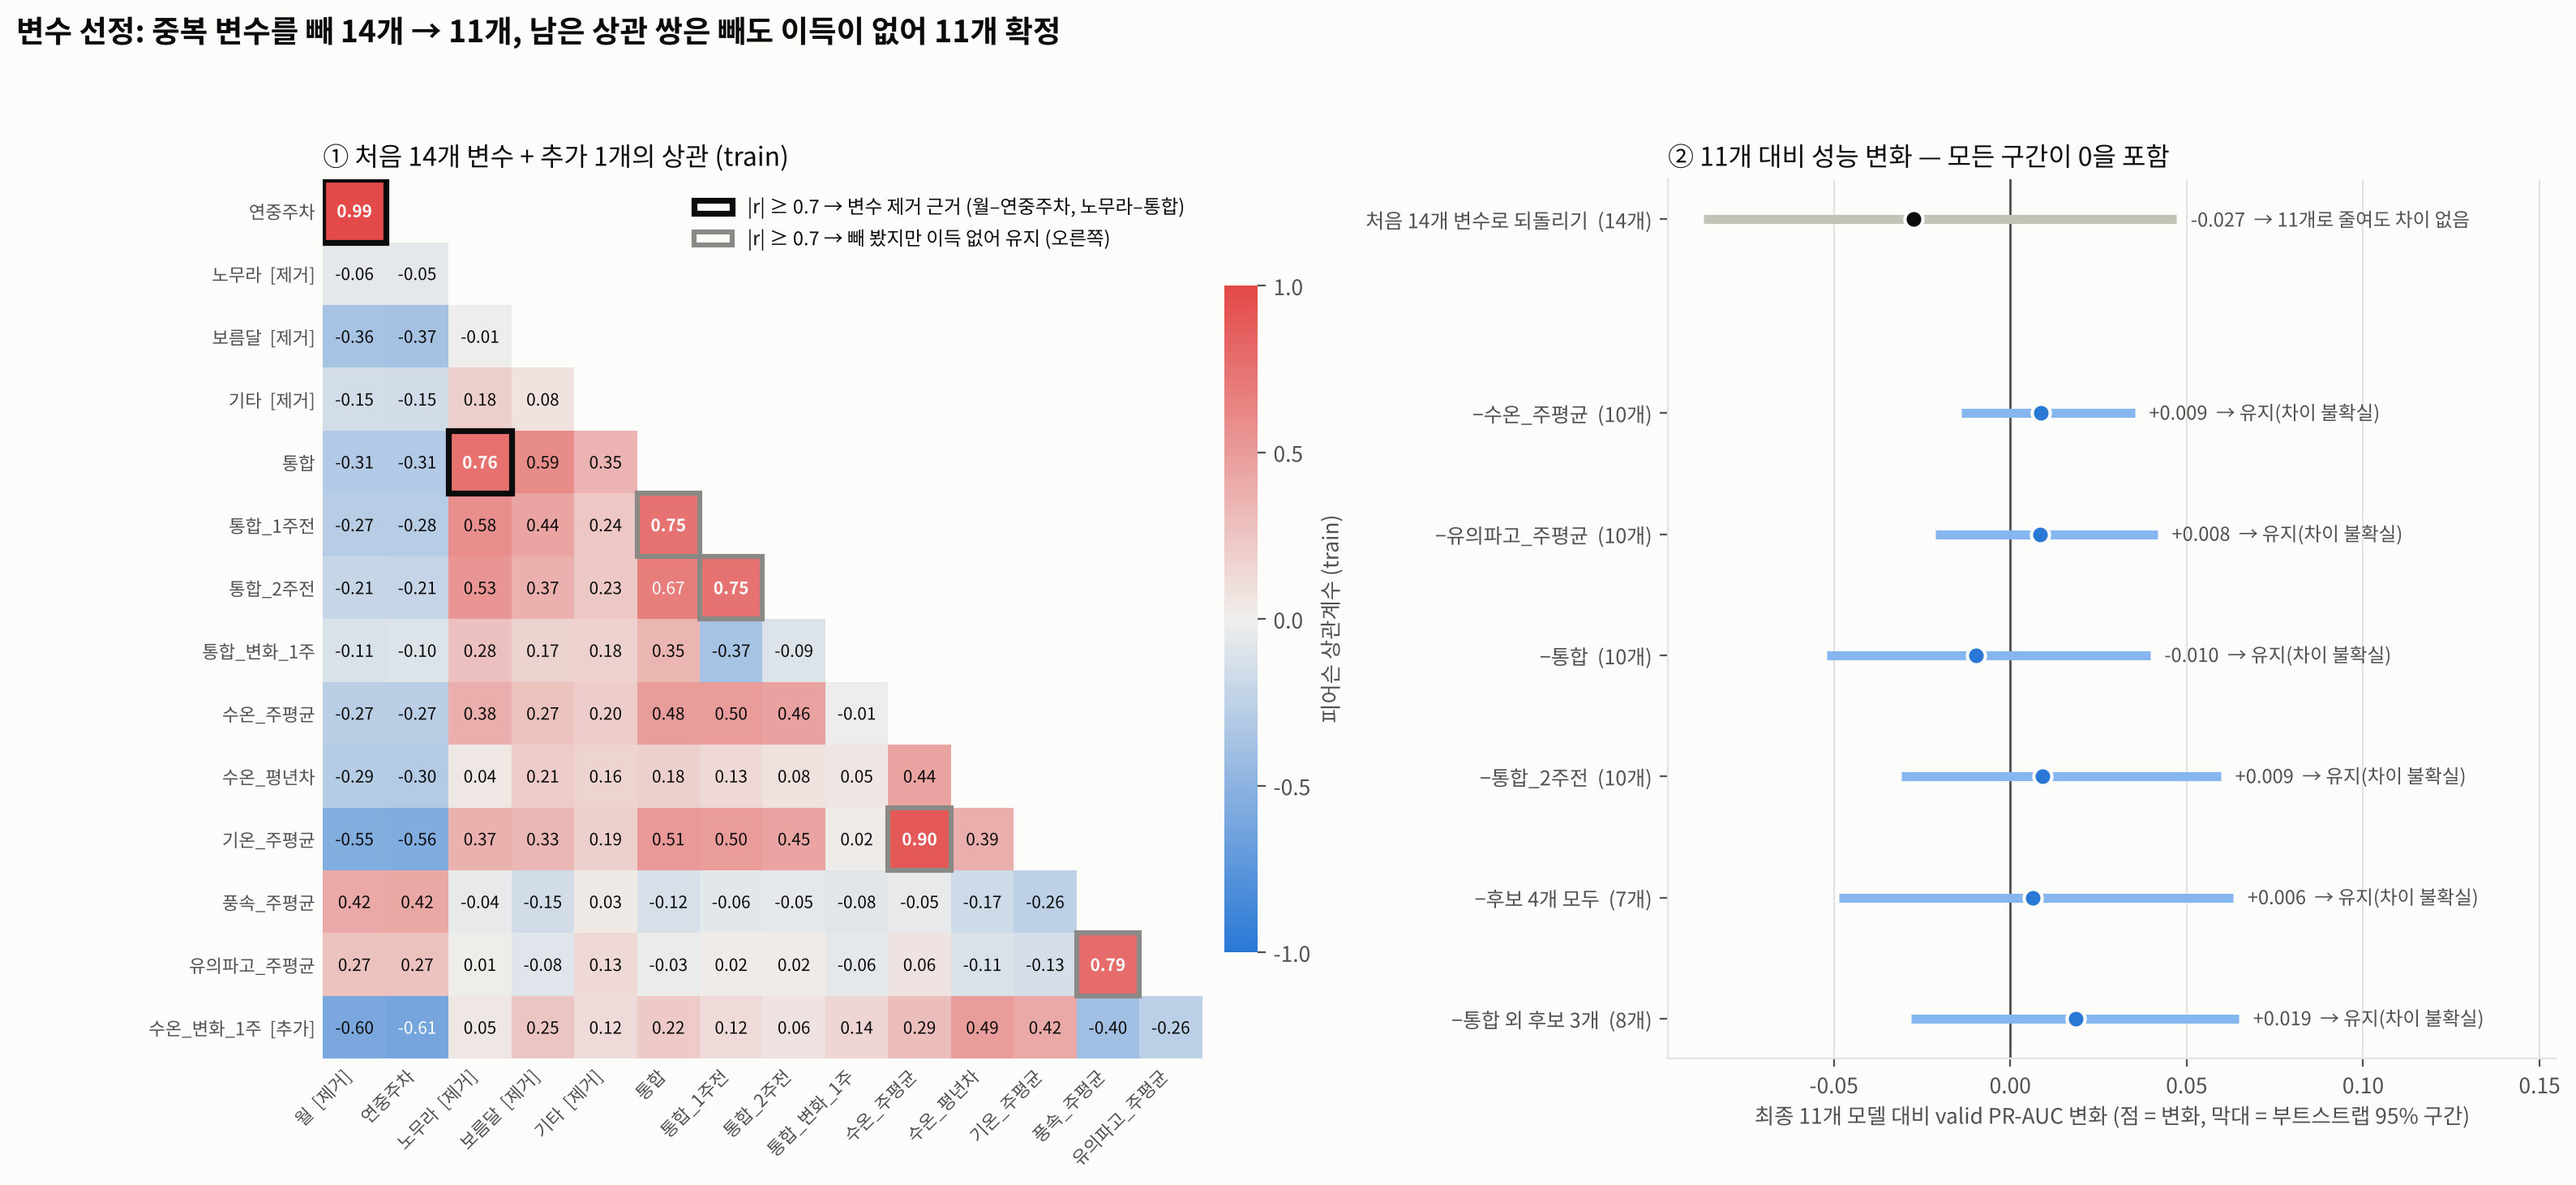

저장: 그림/변수선정_상관행렬.png


In [8]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle, Patch

FIG = "그림"
os.makedirs(FIG, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, RED, MID = "#2a78d6", "#e34948", "#f0efec"
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(name in f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = name
        break
plt.rcParams.update({"axes.unicode_minus": False, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "text.color": INK, "font.size": 9.5})

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 7.4), gridspec_kw={"width_ratios": [1.25, 1]})

# (왼쪽) 처음 14개 + 추가 1개의 상관행렬 (train)
Fn = F15
cv = corr15.loc[Fn, Fn].values
mask = np.triu(np.ones_like(cv, dtype=bool))
cmap = LinearSegmentedColormap.from_list("div", [BLUE, MID, RED])
im = ax.imshow(np.ma.masked_where(mask, cv), cmap=cmap, vmin=-1, vmax=1)
kept_pairs = {frozenset((a, b)) for a, b, _ in pairs}
for i in range(len(Fn)):
    for j in range(i):
        v = cv[i, j]
        a_, b_ = Fn[i], Fn[j]
        strong = abs(v) >= THRESHOLD
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if abs(v) >= 0.6 else INK, fontweight="bold" if strong else None)
        if strong and (a_ in REMOVED or b_ in REMOVED):
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=2.6))
        elif strong and frozenset((a_, b_)) in kept_pairs:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="#8a8985", lw=2.2))
label = lambda f: f"{f}  [제거]" if f in REMOVED else (f"{f}  [추가]" if f in ADDED else f)
ax.set_xticks(range(len(Fn))); ax.set_xticklabels([label(f) for f in Fn], rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(Fn))); ax.set_yticklabels([label(f) for f in Fn], fontsize=8)
ax.set_xlim(-0.5, len(Fn) - 1.5); ax.set_ylim(len(Fn) - 0.5, 0.5)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1]); cb.outline.set_visible(False)
cb.set_label("피어슨 상관계수 (train)", color=INK2)
ax.legend(handles=[Patch(fc="none", ec=INK, lw=2.6, label="|r| ≥ 0.7 → 변수 제거 근거 (월–연중주차, 노무라–통합)"),
                   Patch(fc="none", ec="#8a8985", lw=2.2, label="|r| ≥ 0.7 → 빼 봤지만 이득 없어 유지 (오른쪽)")],
          loc="upper right", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=8.5)
ax.set_title("① 처음 14개 변수 + 추가 1개의 상관 (train)", loc="left", fontsize=11.5, color=INK)

# (오른쪽) valid PR-AUC 변화 (11개 기준) + 95% 구간
sv = summ.iloc[1:].copy()
order_names = ["처음 14개 변수"] + [n for n in sv.index if n != "처음 14개 변수"]
sv = sv.loc[order_names].iloc[::-1]
yy = np.arange(len(sv)).astype(float)
yy[-1] += 0.6                                             # 처음 14개 행은 위로 띄움
ax2.axvline(0, color=INK2, lw=1)
for y_, (n, r) in zip(yy, sv.iterrows()):
    c1, c2 = ("#c3c2b7", INK) if n == "처음 14개 변수" else ("#86b6ef", BLUE)
    ax2.hlines(y_, r["valid_변화_95%하한"], r["valid_변화_95%상한"], color=c1, lw=4)
    ax2.plot(r["valid_변화"], y_, "o", color=c2, ms=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax2.text(r["valid_변화_95%상한"] + 0.004, y_, f"{r['valid_변화']:+.3f}  → {r['판단']}", va="center", fontsize=8.5, color=INK2)
names = [f"{n}  ({int(k)}개)" if n != "처음 14개 변수" else f"처음 14개 변수로 되돌리기  (14개)" for n, k in zip(sv.index, sv["변수수"])]
ax2.set_yticks(yy); ax2.set_yticklabels(names, fontsize=9)
lo = min(sv["valid_변화_95%하한"].min(), -0.02); hi = sv["valid_변화_95%상한"].max()
ax2.set_xlim(lo - 0.01, hi + 0.09)
ax2.set_xlabel("최종 11개 모델 대비 valid PR-AUC 변화 (점 = 변화, 막대 = 부트스트랩 95% 구간)")
ax2.grid(True, axis="x", color=GRID, lw=0.8); ax2.set_axisbelow(True)
for sp in ["top", "right"]: ax2.spines[sp].set_visible(False)
ax2.set_title("② 11개 대비 성능 변화 — 모든 구간이 0을 포함", loc="left", fontsize=11.5, color=INK)

fig.suptitle("변수 선정: 중복 변수를 빼 14개 → 11개, 남은 상관 쌍은 빼도 이득이 없어 11개 확정", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(f"{FIG}/변수선정_상관행렬.png", dpi=200)
plt.show()
print(f"저장: {FIG}/변수선정_상관행렬.png")

## 6. 저장

In [9]:
out.to_csv(f"{OUT_DIR}/상관기반_변수제거.csv", encoding="utf-8-sig")
corr.round(3).to_csv(f"{OUT_DIR}/상관_입력변수_train.csv", encoding="utf-8-sig")
print(f"저장: {OUT_DIR}/상관기반_변수제거.csv, 상관_입력변수_train.csv")

저장: 결과/상관기반_변수제거.csv, 상관_입력변수_train.csv


## 결론
- 처음 14개 → 11개: 월(연중주차와 0.99)과 어종별 출현율 3개(통합 출현율에 포함, 노무라–통합 0.76)를 빼고 수온_변화_1주를 추가. 처음 14개로 되돌려도 valid 성능 차이가 우연 범위 안 → 변수를 줄여도 성능 손실 없음
- 11개 안의 상관 쌍(수온–기온, 풍속–파고, 통합–1주 전, 1주 전–2주 전)은 빼 봐도 성능 차이가 우연 범위 안
- 따라서 입력 변수 11개를 최종 확정. 비교 모델 4개와 서비스 모델(05) 모두 같은 11개 사용
- 계수는 서로 겹치는 정보를 나눠 가지므로 '출현율', '계절', '수온·기상' 묶음 단위로 해석